## Линейная регрессия

Одним из важных алгоритмов машинного обучения является **линейная регрессия**. Рассмотрим постановку задачи, а также разберём алгоритм на практических примерах

**Линейная регрессия** - способ найти линейную зависимость (в случае трёхмерного пространства, например, это будет плоскость), которая лучше всего описывает связь между разными величинами.

С помощью линейной регрессии можно решать большое количество задач, например:
- прогноз числовых значений
- поиск главных факторов
- определение трендов
- проверка идей

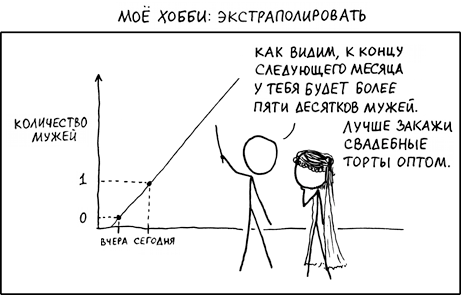

Прежде, чем использовать названный метод, необходимо проверить тот факт, что обучающие данные действительно представляют линейную зависимость. Если же связь будет носить более сложный характер, то линейная регрессия будет ошибаться.

### Постановка задачи и описание модели

Простейший пример постановки задачи линейной регрессии - **метод наименьших квадратов** (ordinary least squares, OLS).
Пусть задана некоторая зависимость объясняемой (целевой) переменной от объясняющих её факторов. В случае рассматриваемой задачи такая зависимость будет линейной, запишем её в виде математической формулы:
$$y_i = \omega_0 + \sum_{i=1}^{d}{\omega_ix_i} + \epsilon_i, $$ где $y$ - объясняемая переменная, $x_i$ - объясняющий фактор (другими словами, известные данные или наблюдения), $w_i$ - коэффициенты (веса), $w_0$ - свободный член, $\epsilon_i$ - случайная непрогнозируемая ошибка.

Если добавить в наблюдения фиктивную размерность $x_0$, тогда предыдущую формулу можно будет записать в более компактном виде, записав свободный член под суммой:
$$y_i = \sum_{i=0}^{d}{\omega_ix_i} + \epsilon_i = \vec{\omega}^T\vec{x} + \epsilon_i$$
Если мы будем рассматривать матрицу наблюдений-признаков $X$, то в таком случае необходимо будет добавить единичный столбец слева, и запись примет следующий вид:
$$\vec{y} = X\vec{\omega} + \epsilon,$$
где
- $\vec{y} \in \mathbb{R}^n$ - вектор прогнозируемой переменной
- $\vec{\omega}$ - вектор параметров модели
- $X$ - матрица наблюдений и признаков, каждая строка представляет отдельные наблюдения, слева дописан единичный столбец, имеет размерность $n \times (d + 1)$, где $n$ - число наблюдлений, а $d$ - число признаков
- $\epsilon$ - случайная ошибка модели

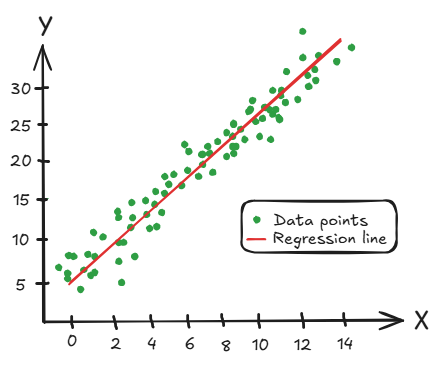

Таким образом, мы хотим найти функцию, которая будет "лучшим" образом приближать зависимость между целевой переменной и наблюдениями. Понятие "лучшим" требует формализации, иначе не совсем понятно в каком смысле оно применяется. Простыми словами, мы должны научиться каким-то образом измерять качество полученной модели (функции) и минимизировать её ошибку, изменяя некоторым образом обучаемые параметры (веса). Функция оценивающая ошибки модели, традиционно называется функцией потерь, функционалом качества или лоссом (англ. loss function). Интуитивно понятно, что для текущей задачи нам необходимо взять предсказание нашей модели и каким-то образом сравнить его с истинными значениями. Обычно в качестве функции потерь в задаче линейной регрессии используется сумма квадратов ошибок или **среднеквадратическое отклонение** (Mean Squared Error, MSE). 

Функция потерь задаётся следующим образом:

$$\large \begin{array}{rcl}\mathcal{L}\left(\textbf{X}, \textbf{y}, \textbf{w} \right) &=& \frac{1}{2n} \sum_{i=1}^n \left(y_i - \textbf{w}^{\text{T}} \textbf{x}_i\right)^2 \\
&=& \frac{1}{2n} \left\| \textbf{y} - \textbf{X} \textbf{w} \right\|_2^2 \\
&=& \frac{1}{2n} \left(\textbf{y} - \textbf{X} \textbf{w}\right)^{\text{T}} \left(\textbf{y} - \textbf{X} \textbf{w}\right)
\end{array}$$

Для каждой конкретной линейной функции, которая задаётся весами, мы получаем число, которое оценивает насколько точно наша модель париближает значения объясняемой переменной. Чем меньше будет это число (ошибка), тем точнее наша функция будет описывать зависимость. Тогда, чтобы найти лучшую модель, нам необходимо минимизировать функцию потерь по параметрам $\omega$. Задача сводится к минимизации функции потерь:

$$\left\| \textbf{y} - \textbf{X} \textbf{w} \right\|_2^2 \to \min_{\omega}$$    

Теперь более подробно попытаемся обосновать, почему в качестве функции потерь используется сумма квадратов ошибок, решим поставленную задачу 

### Метод наименьших квадратов

#### Ограничения

Чтобы применение модели линейной регрессии было возможно для конкрентной задачи, необходимо соблюдение ряда ограничений, вытекающих из теоремы [Гаусса-Маркова](https://ru.wikipedia.org/wiki/%D0%A2%D0%B5%D0%BE%D1%80%D0%B5%D0%BC%D0%B0_%D0%93%D0%B0%D1%83%D1%81%D1%81%D0%B0_%E2%80%94_%D0%9C%D0%B0%D1%80%D0%BA%D0%BE%D0%B2%D0%B0).

1. $y = \vec{\omega}^T\vec{x} + \epsilon$, т.е. модель состоит из фиксированной части ($y = \vec{\omega}^T\vec{x}$) и случайной части ($\epsilon$), модель *линейна по параметрам* (важно, что модель должна быть линейной именно по параметрам, а не наблюдениям, так как например использование квадрата признака является одним из приёмом feature engineering).
2. все $x_i$ детерменированы и не все равны между собой, иными словами, переменные не должны быть постоянными.
3. $\operatorname{rank} X = d + 1$, т.е. отсутствие мультиколлинеарности в данных (популярным примером мультиколлинеарности является наличие составного признака, приблизительно совпадающего с суммой двух других)
4. $\forall{i}: \mathbb{E}[\epsilon_{i}] = 0$, матожидание случайных ошибок равно нулю, не должно быть причины для того, чтобы случайный член порождал бо́льшую ошибку в одних наблюдениях, чем в других.
5. $\forall i \neq j: \operatorname{Cov}(\epsilon_i, \epsilon_j) = 0$, случайные ошибки не скоррелированы.

Из этих свойств следует, что получаемая с помощью МНК (метода наименьших квадратов) оценка является несмещённой $\mathbb{E}[\hat{\vec{\omega}}] = \vec{\omega}$.

Добавим ещё одно ограничение, называемое *гомоскедатичностью* в нашу систему:

6. $\forall i: \text{Var}\left(\epsilon_i\right) = \sigma^2 < \infty$, дисперсия случайных ошибок одинакова и конечна.

Из полученной системы ограничений, накладываемых на модель следует, что МНК даёт оценку максимального правдоподобия (Maximum Likelihood Estimation), следовательно при использовании МНК дисперсия несмещённой оценки будет минимальной $\text{Var}
\left(\hat{\vec{\omega}}\right) \to \min$.

Определим также формально используемые при объяснении термины из математической статистики.

Каждый элемент выборки независимых одинаково расмпределенных случайных величин (i.i.d) $X_1,…,X_n$ можно рассматривать как значение случайной величины из некоторого распределения с неизвестным параметром $\theta$.

Всякую оценку этого параметра $\hat{\theta}(X_1,…,X_n)$ можно также считать случайной величиной.

*Опр 1.* Оценка $\hat{\theta}(X_1,…,X_n)$ параметра $\theta$ называется несмещённой, если $\mathbb{E}[\hat{\theta}] = \theta$. Несмещённость оценки означает, что она в среднем будет равна истинному значению параметра.
